# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_: 
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how Euler's method and RK4 work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: De Casa, Samantha Claire
- _Student No._: 2023-15141
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Description](Figure_131.png)

**Figure 1.1** 

Figure 1.1 shows the Lorenz attractor, a two-winged, butterfly-like strange attractor in phase space.


![Description](Figure_1321.png)

**Figure 2.1**

![Description](Figure_1322.png)

**Figure 2.2**

![Description](Figure_1323.png)

**Figure 2.3** 


Figures 2.1, 2.2, and 2.3 show the Van-der-Pol oscillator phase space plot for $\mu=1, 2, 4$.


### Report discussion
The van der Pol oscillator phase space plot maps position $x$ against velocity $\frac{dx}{dt}$ to show how trajectories evolve over time and settle into a limit cycle. The parameter $\mu$ controls nonlinear damping strength. When $\mu=1$, the trajectory is smooth and virtually elliptical. When $\mu=2$, it appears slightly elongated. When $\mu=4$, the trajectory is significantly more elongated or distorted. This implies that increasing $\mu$ changes the oscillator from a smooth sinusoidal-like motion to nonlinear periodic motion. Unlike the van der Pol oscillator, the Lorenz system exhibits chaotic behavior. Here the trajectory continuously moves around the two distinct lobes that resemble the wings of a butterfly, switching between them in an irregular manner.

Euler's method works by calculating the slope of a function at one point and then using that slope to estimate the next point. In this method, the assumption is that the slope is constant throughout each time step. Unlike Euler's method which calculates only one slope per time step, RK4 works by calculating four slopes at a time to accurately estimate the next point. Instead of assuming that the slope is constant throughout each time step, it considers how the slope changes within each time interval. However, while RK4 produces a much more accurate numerical approximation than Euler's method, it is more complicated and computationally expensive. Therefore, Euler's method is best to use when solving simple problems at the cost of a relatively higher numerical error, while RK4 is best to use when numerical accuracy is of utmost importance.

---
## Section 2: Code

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

Hint: you may use `euler()` or `rk4()` in Section 3.

In [2]:
def lorenz(sigma=10, rho=28, beta=8/3, h=0.001):
    t = np.arange(0, 50 + h, h)
    n = len(t)

    x = np.zeros(n)
    y = np.zeros(n)
    z = np.zeros(n)

    x[0] = 0 #initial conditions
    y[0] = 1
    z[0] = 0

    for i in range(n - 1):
        dx = sigma * (y[i] - x[i]) #Lorenz equations
        dy = x[i] * (rho - z[i]) - y[i]
        dz = (x[i] * y[i]) - (beta * z[i])

        x[i+1] = x[i] + (h * dx)
        y[i+1] = y[i] + (h * dy)
        z[i+1] = z[i] + (h * dz)

    return t, x, y, z

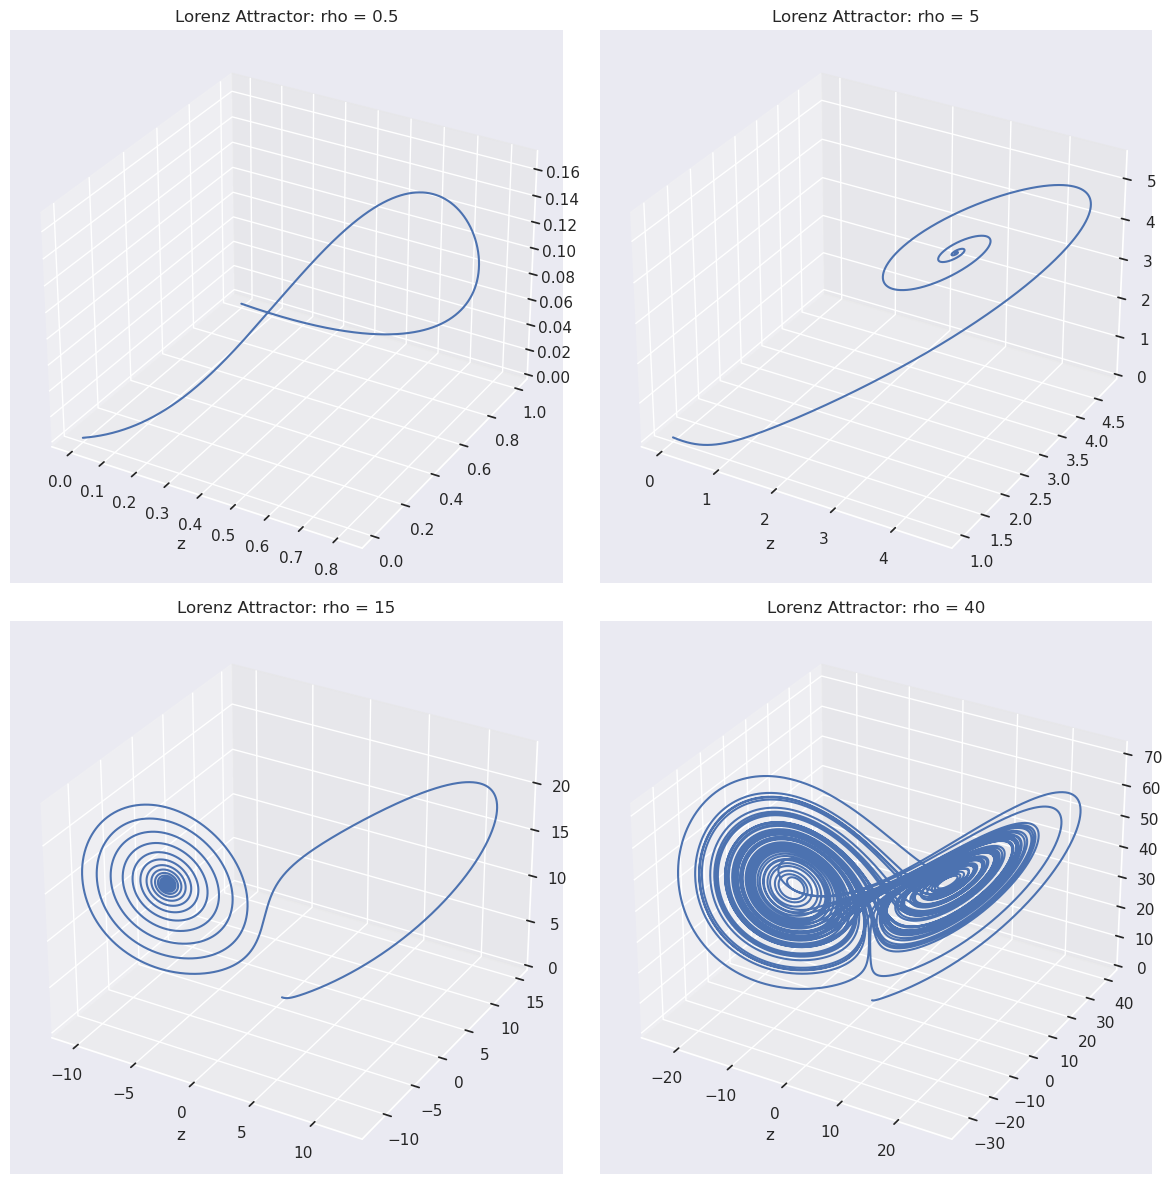

In [28]:
sigma = 10
beta = 8/3
rho_values = [0.5, 5, 15, 40]

fig = plt.figure(figsize=(12, 12))

for i, rho in enumerate(rho_values):
    t, x, y, z = lorenz(sigma, rho, beta)

    ax = fig.add_subplot(2, 2, i+1, projection='3d')

    ax.plot(x, y, z)
    ax.set_title(f'Lorenz Attractor: rho = {rho}')
    ax.set_xlabel('x')
    ax.set_xlabel('y')
    ax.set_xlabel('z')

plt.tight_layout()
plt.show()

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

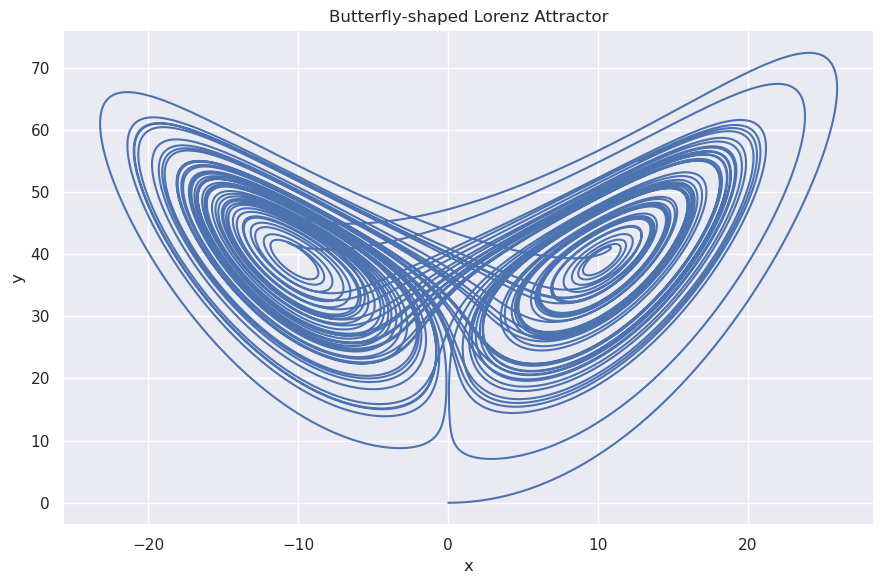

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(x, z)
ax.set_title('Butterfly-shaped Lorenz Attractor')
ax.set_xlabel('x')
ax.set_ylabel('y')

plt.tight_layout()
plt.savefig('Figure_131.png')
plt.show()

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

In [5]:
def harmonic(x0, y0, omega=1, h=0.01):
    t = np.arange(0, 50 + h, h)
    n = len(t)

    x = np.zeros(n)
    y = np.zeros(n)

    x[0] = x0 #initial conditions
    y[0] = y0

    for i in range(n - 1):
        dx = y[i]
        dy = -(omega**2) * x[i]

        x[i+1] = x[i] + (h * dx)
        y[i+1] = y[i] + (h * dy)

    return t, x, y

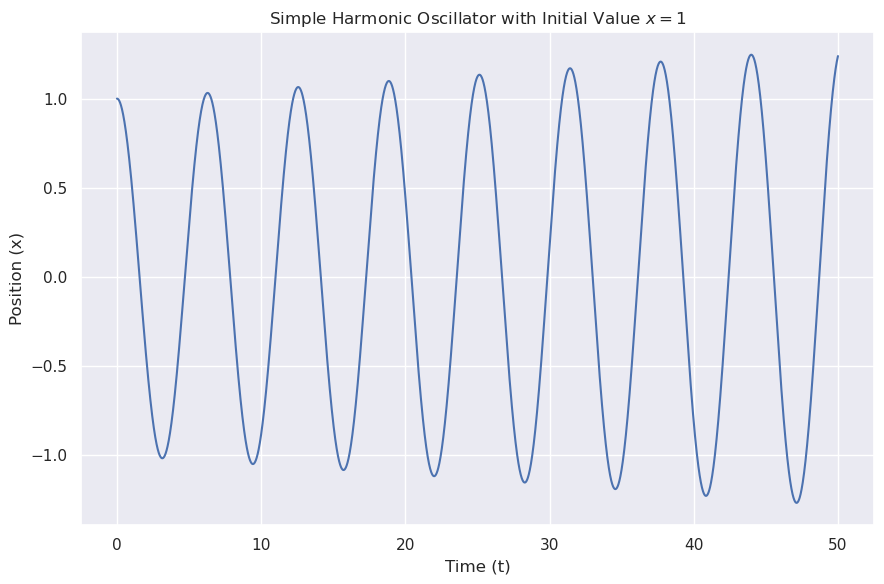

In [6]:
#for x=1, y=0
t, x, y = harmonic(1, 0)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(t, x)
ax.set_title(r'Simple Harmonic Oscillator with Initial Value $x = 1$')
ax.set_xlabel('Time (t)')
ax.set_ylabel('Position (x)')

plt.tight_layout()
plt.show()

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

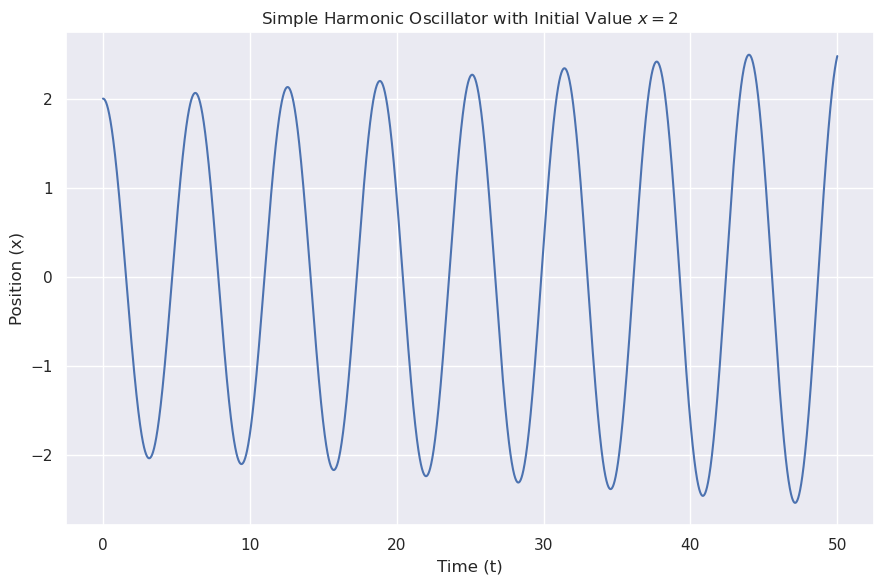

In [7]:
#for x=2, y=0
t, x, y = harmonic(2, 0)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(t, x)
ax.set_title(r'Simple Harmonic Oscillator with Initial Value $x = 2$')
ax.set_xlabel('Time (t)')
ax.set_ylabel('Position (x)')

plt.tight_layout()
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

In [8]:
def anharmonic(x0, y0, omega=1, h=0.01):
    t = np.arange(0, 50 + h, h)
    n = len(t)

    x = np.zeros(n)
    y = np.zeros(n)

    x[0] = x0 #initial conditions
    y[0] = y0

    for i in range(n - 1):
        dx = y[i]
        dy = -(omega**2) * (x[i])**3

        x[i+1] = x[i] + (h * dx)
        y[i+1] = y[i] + (h * dy)

    return t, x, y

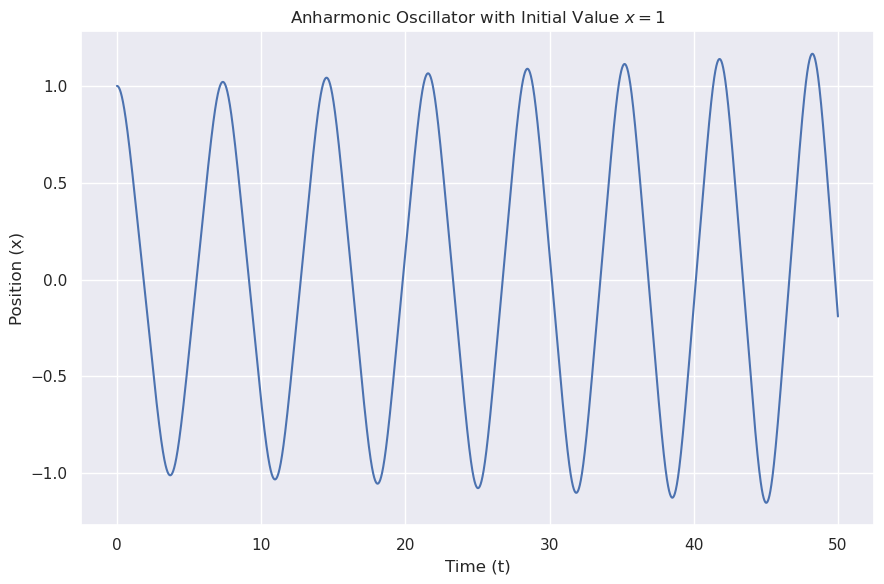

In [9]:
#for x=1, y=0
t, x, y = anharmonic(1, 0)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(t, x)
ax.set_title(r'Anharmonic Oscillator with Initial Value $x = 1$')
ax.set_xlabel('Time (t)')
ax.set_ylabel('Position (x)')

plt.tight_layout()
plt.show()

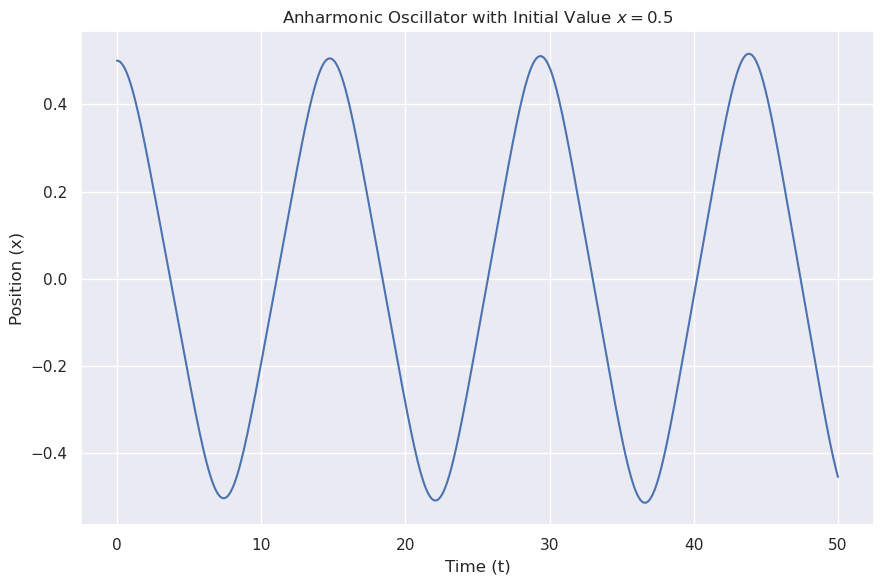

In [10]:
#for x=0.5, y=0
t, x, y = anharmonic(0.5, 0)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(t, x)
ax.set_title(r'Anharmonic Oscillator with Initial Value $x = 0.5$')
ax.set_xlabel('Time (t)')
ax.set_ylabel('Position (x)')

plt.tight_layout()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

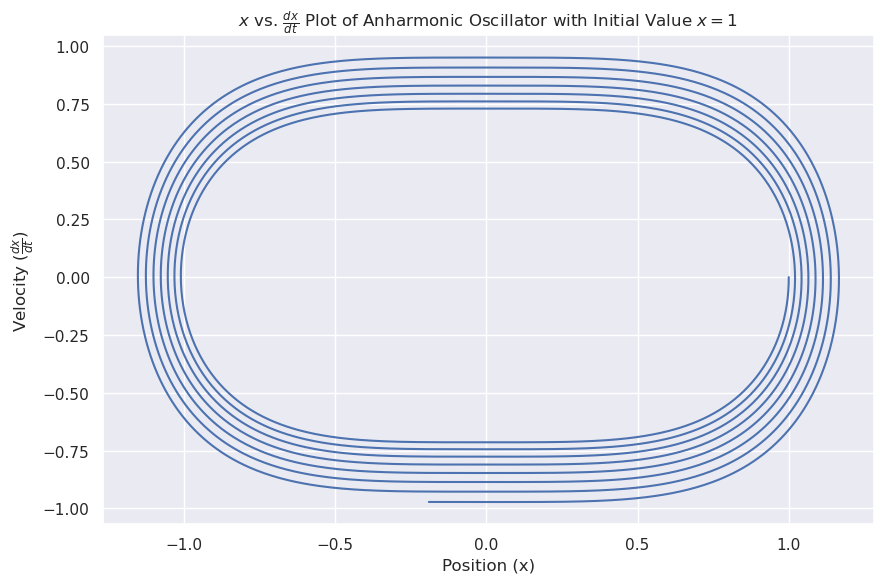

In [11]:
#for x=1, y=0
t, x, y = anharmonic(1, 0)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(x, y)
ax.set_title(r'$x$ vs. $\frac{dx}{dt}$ Plot of Anharmonic Oscillator with Initial Value $x = 1$')
ax.set_xlabel('Position (x)')
ax.set_ylabel(r'Velocity $(\frac{dx}{dt})$')

plt.tight_layout()
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

In [34]:
def van_der_pol(x0, y0, mu=1, h=0.001):
    t = np.arange(0, 20 + h, h)
    n = len(t)

    x = np.zeros(n)
    y = np.zeros(n)

    x[0] = x0 #initial conditions
    y[0] = y0

    for i in range(n - 1):
        dx = y[i]
        dy = mu * (1 - x[i]**2) * y[i] - x[i]

        x[i+1] = x[i] + (h * dx)
        y[i+1] = y[i] + (h * dy)

    return t, x, y

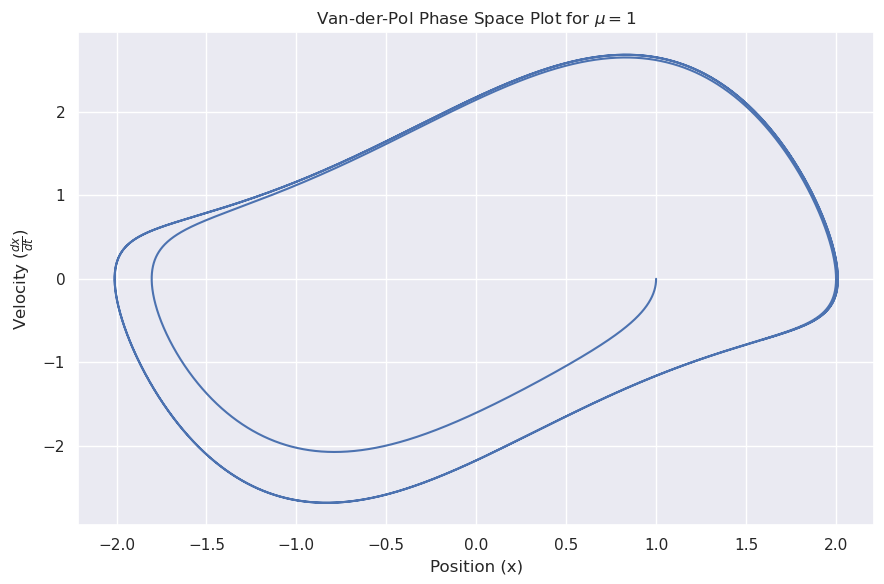

In [35]:
#for mu=1
t, x, y = van_der_pol(1, 0)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(x, y)
ax.set_title(r'Van-der-Pol Phase Space Plot for $\mu=1$')
ax.set_xlabel('Position (x)')
ax.set_ylabel(r'Velocity $(\frac{dx}{dt})$')

plt.tight_layout()
plt.savefig('Figure_1321.png')
plt.show()

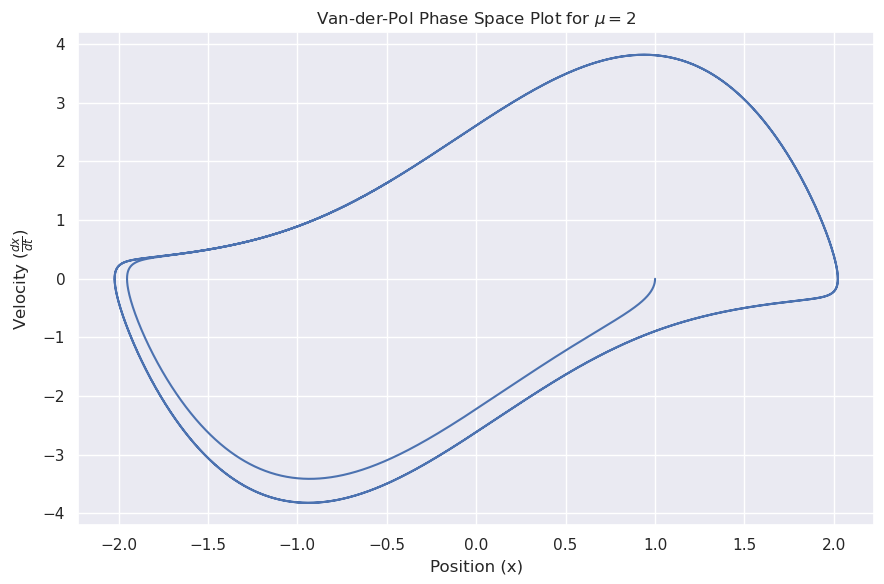

In [36]:
#for mu=2
t, x, y = van_der_pol(1, 0, mu=2)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(x, y)
ax.set_title(r'Van-der-Pol Phase Space Plot for $\mu=2$')
ax.set_xlabel('Position (x)')
ax.set_ylabel(r'Velocity $(\frac{dx}{dt})$')

plt.tight_layout()
plt.savefig('Figure_1322.png')
plt.show()

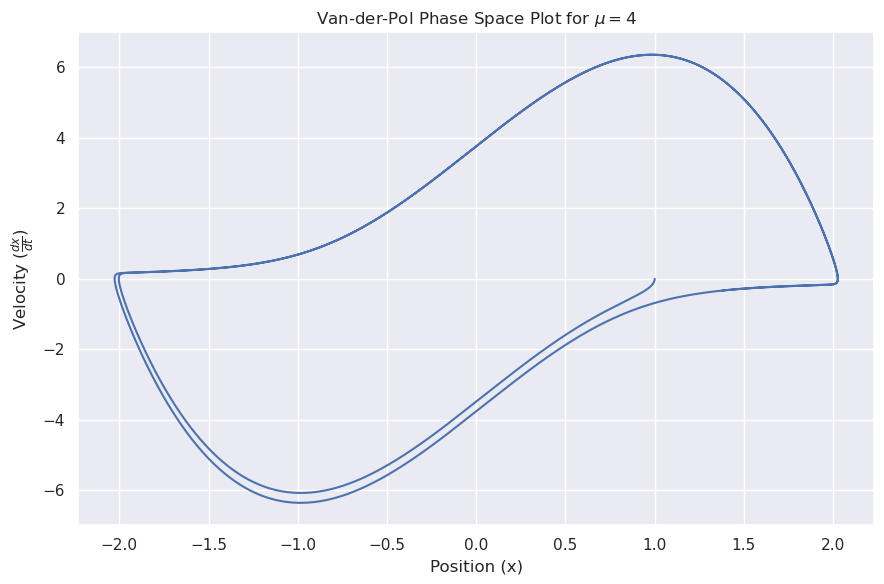

In [37]:
#for mu=4
t, x, y = van_der_pol(1, 0, mu=4)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(x, y)
ax.set_title(r'Van-der-Pol Phase Space Plot for $\mu=4$')
ax.set_xlabel('Position (x)')
ax.set_ylabel(r'Velocity $(\frac{dx}{dt})$')

plt.tight_layout()
plt.savefig('Figure_1323.png')
plt.show()

#### Problem code summary

The purpose of these algorithms is to solve first- and second-order ordinary differential equations. Here I specifically chose to use Euler's method because I found it easier to implement in code.

---
## Section 3: Notes

In [16]:
import numpy as np

# Ricatti equation (mildly nonlinear)
def f(x,y):
    return - (30/(1-x**2)) + ((2*x)/(1-x**2))*y - y**2

### IVPs

#### 1st order ODE solver: Euler's method

In [17]:
# forward Euler's method
def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

#### 1st order ODE solver: Rungke-Kutta method

In [18]:
# 4th order Runge-Kutta method
def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

In [19]:
# execution
a, b, n, yinit = 0.05, 0.49, 12, 19.53
xs, ys = euler(f,a,b,n,yinit); print(ys)
xs, ys = rk4(f,a,b,n,yinit); print(ys)

[ 19.53         3.14847227   1.56501191   0.26296871  -0.97182666
  -2.28204589  -3.81903888  -5.80936521  -8.6780744  -13.37838499
 -22.50759395 -45.29198435]
[ 19.53        10.16782416   6.37032643   4.11921483   2.48829431
   1.12081032  -0.17770512  -1.56533384  -3.24322678  -5.58940124
  -9.6041146  -19.50349262]


#### 2nd-order ODE: RK4

In [20]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])
    
def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Updated to handle arrays (systems of ODEs)
def euler(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

def rk4(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

#### Shooting methods

In [22]:
def secant(f,x0,x1,kmax=200,tol=1.e-8):
    f0 = f(x0)
    for k in range(1,kmax):
        f1 = f(x1)
        ratio = (x1 - x0)/(f1 - f0)
        x2 = x1 - f1*ratio
        xdiff = abs(x2-x1)
        x0, x1 = x1, x2
        f0 = f1
        rowf = "{0:2d}{1:1.16f} {2:1.16f} {3:1.16f}"
        print(rowf.format(k,x2,xdiff,abs(f(x2))))
        if abs(xdiff/x2) < tol:
            break
    else:
        x2 = None
    
    return x2

def shoot(sig):
    a, b, n = 0.05, 0.49, 100
    yinits = np.array([0.0926587109375, sig])
    xs, ys = rk4gen(fs,a,b,n,yinits)
    wfinal = 0.11177050858750004
    return ys[-1, 0] - wfinal

wder = secant(shoot,0.,1.)
print(wder)

 11.8096210699240751 0.8096210699240751 0.0000000000000001
 21.8096210699240738 0.0000000000000013 0.0000000000000001
1.8096210699240738


#### BVP matrix

In [23]:
from gauelimpivot import gauelimpivot
import numpy as np

def matsetup(a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    A = np.zeros((n,n))
    np.filldiagonal(A, -2 + 30*h**2/(1-xs**2))
    A[0,0] = 1; A[-1,-1] = 1
    np.filldiagonal(A[1:,:], 1 + h*xs[1:]/(1-xs[1:]**2))
    A[-1,-2] = 0
    np.filldiagonal(A[:,1:], 1 - h*xs/(1-xs**2))
    A[0,1] = 0
    bs = np.zeros(n)
    bs[0] = 0.0926587109375
    bs[-1] = 0.11177050858750004
    return A, bs

def riccati(a,b,n):
    A, bs = matsetup(a, b, n)
    ws = gauelimpivot(A, bs)
    return ws

a, b, n = 0.05, 0.49, 400
ws = riccati(a, b, n); print(ws)

ModuleNotFoundError: No module named 'gauelimpivot'

#### Shooting method

In [ ]:
from secant import secant
import numpy as np

def fs(x,yvals,s):
    q = 1.5
    y0, y1 = yvals
    f0 = y1
    f1 = (2*q*np.cos(2*x) - s)*y0
    return np.array([f0, f1])

def rk4geneig(fs,a,b,n,yinits,s):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals,s)
        k1 = h*fs(x+h/2, yvals+k0/2,s)
        k2 = h*fs(x+h/2, yvals+k1/2,s)
        k3 = h*fs(x+h, yvals+k2,s)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys
    
def shoot(s):
    a, b, n = 0, 2*np.pi, 500
    yinits = np.array([0., 5.])
    xs, ys = rk4geneig(fs,a,b,n,yinits,s)
    wfinal = 0.
    return ys[-1, 0] - wfinal

for sinit in (-0.4, 3.3, 8.5):
    sval = secant(shoot,sinit,sinit+0.5)
    print(sval, end=" ")

#### Matrix approach

In [ ]:
from qrmet import qrmet
import numpy as np

def matsetup(q,n):
    h = 2*np.pi/n
    xs = np.arange(n)*h
    A = np.zeros((n,n))
    np.filldiagonal(A, -2 - 2*h**2*q*np.cos(2*xs))
    np.filldiagonal(A[1:,:], 1)
    np.filldiagonal(A[:,1:], 1)
    A[0,-1] = 1
    A[-1,0] = 1
    return A

def mathieu(q,n):
    A = matsetup(q, n)
    qreigvals = qrmet(A,200)
    h = 2*np.pi/n
    qreigvals = np.sort(-qreigvals/h**2)
    return qreigvals

q, n = 1.5, 200
qreigvals = mathieu(q, n)
print(qreigvals[:6])

### Plotting

In [ ]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)


# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{dy_0}{dt} &= y_1 \\
\frac{dy_1}{dt} &= -\frac{g}{l}\sin(y_0)
\end{align}

In [ ]:
def pendulum_ode(t, Y):
    g = 9.81
    l = 1.0
    theta, omega = Y
    return np.array([omega, -(g/l)*np.sin(theta)])

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = [np.pi/4, 0.0]
t, Y_euler = euler(pendulum_ode, 0, 10, 1000, yinit)
t, Y_rk4 = rk4(pendulum_ode, 0, 10, 1000, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()